---
format: revealjs
---

<span style= "color: yellow; font-size:42px;"> A Lecture on Simple Linear Regression </span>

Introduction
Welcome to this lecture on simple linear regression! Our goal is to understand the relationship between two variables and to build a model that can predict one variable based on the value of the other.



For this analysis, we will use the provided dataset, which contains Attendance_Hours and Final_Marks. We'll explore if there is a linear relationship between the hours a student attends and their final marks, and then build a model to predict the marks.

<span style= "color: deepskyblue; font-size:32px;">**Step 1: Loading and Exploring the Data**</span>

In [11]:
#| echo: True
import pandas as pd
import numpy as np

# Load the data from the provided CSV file.
df = pd.read_csv('../dataset/Study_vs_Score_data.csv')


### <span style= "color: deepskyblue; font-size:32px;">**Step 2: Data Preprocessing**</span>
#### <span style= "color: deepskyblue; font-size:32px;">Data Visualization</span>

In [12]:
# Display the first 5 rows of the dataframe to see what the data looks like.
print(df.head())


   Attendance_Hours  Final_Marks
0         36.217808    58.997409
1         76.550001    71.598279
2         61.239576    72.520777
3         51.906094    69.005976
4         20.921305    53.259605


In [13]:
# Get a summary of the dataframe, including data types and non-null counts.
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Attendance_Hours  1000 non-null   float64
 1   Final_Marks       1000 non-null   float64
dtypes: float64(2)
memory usage: 15.8 KB
None


In [14]:
# Check missing values per column
df.isnull().sum()

Attendance_Hours    0
Final_Marks         0
dtype: int64

Before we build a model, it's crucial to visualize the data. A scatter plot is the perfect tool for this, as it allows us to see if there's a clear linear pattern between Attendance_Hours and Final_Marks. If the points form a rough line, linear regression is a good choice for our model.


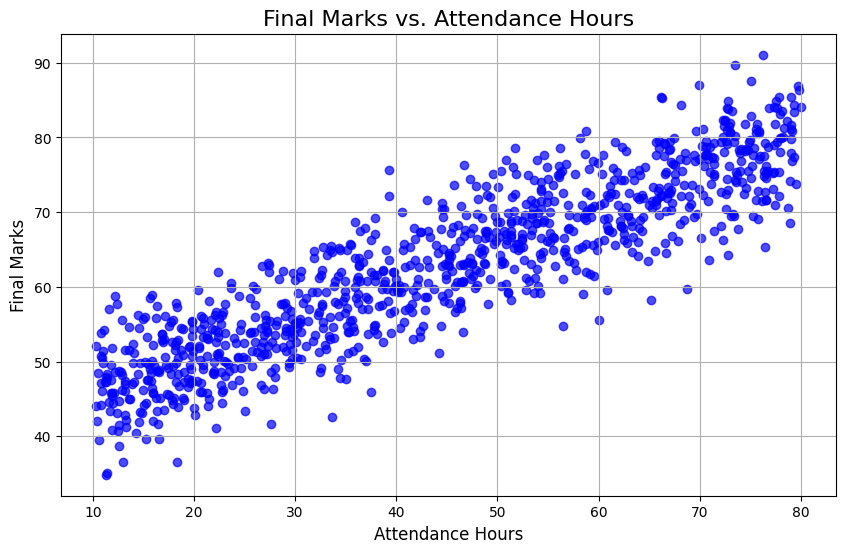

In [15]:
import matplotlib.pyplot as plt

# Create a scatter plot of the two variables.
plt.figure(figsize=(10, 6))
plt.scatter(df['Attendance_Hours'], df['Final_Marks'], color='blue', alpha=0.7)
plt.title('Final Marks vs. Attendance Hours', fontsize=16)
plt.xlabel('Attendance Hours', fontsize=12)
plt.ylabel('Final Marks', fontsize=12)
plt.grid(True)
plt.show()

<span style="color: orange">The scatter plot clearly shows a positive relationship. As the Attendance_Hours increase, the Final_Marks also tend to increase, suggesting that a linear model will be a good fit for this data</span>


#### <span style= "color: deepskyblue; font-size:32px;">Cost Function</span>

The Cost Function Linear regression works by finding the "best fit" line for our data. But what exactly does "best fit" mean? It's the line that minimizes the difference between the actual data points and the points on our predicted line.

To measure this difference, we use a cost function (also known as a loss function). A common one is the Mean Squared Error (MSE). The MSE is the average of the squared differences between the predicted values and the actual values.

$$
MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2
$$




Where:

$$
y_i : \text{ actual value}
$$

$$
\hat{y}_i : \text{ predicted value from the model}
$$

$$
n : \text{ number of data points}
$$


<span style = "color: orange">Let's write a simple function to calculate the MSE for any given slope (m) and y-intercept (b).</span>



In [16]:
def mean_squared_error(m, b, X, y):
    """Calculates the mean squared error for a given slope and intercept."""
    y_predicted = m * X + b
    mse = np.mean((y - y_predicted)**2)
    return mse


#### <span style= "color: deepskyblue; font-size:32px;">Define Input and Output</span>

Assume that, from the dataset, the goal is to predict a student’s final mark based on attendance hours. Therefore, attendance hours are defined as the feature (input), and the final mark is defined as the label (output).

In [17]:
X = df[['Attendance_Hours']].values # feature/input
y = df['Final_Marks'].values   #label/output

#### <span style= "color: deepskyblue; font-size:32px;">Split data set into train 80% and test 20%</span>

In [18]:
from sklearn.model_selection import train_test_split
# Split data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)



<span style= "color: deepskyblue; font-size:32px;">**Step 3: Prediction Model: Linear Regression Model**</span>

<span style= "color: deepskyblue; font-size:32px;">1. Linear Regression from Scratch:</span>


To see this in action, let's experiment with a few different lines and see how their MSE changes. Our goal is to find the line that gives us the lowest MSE.

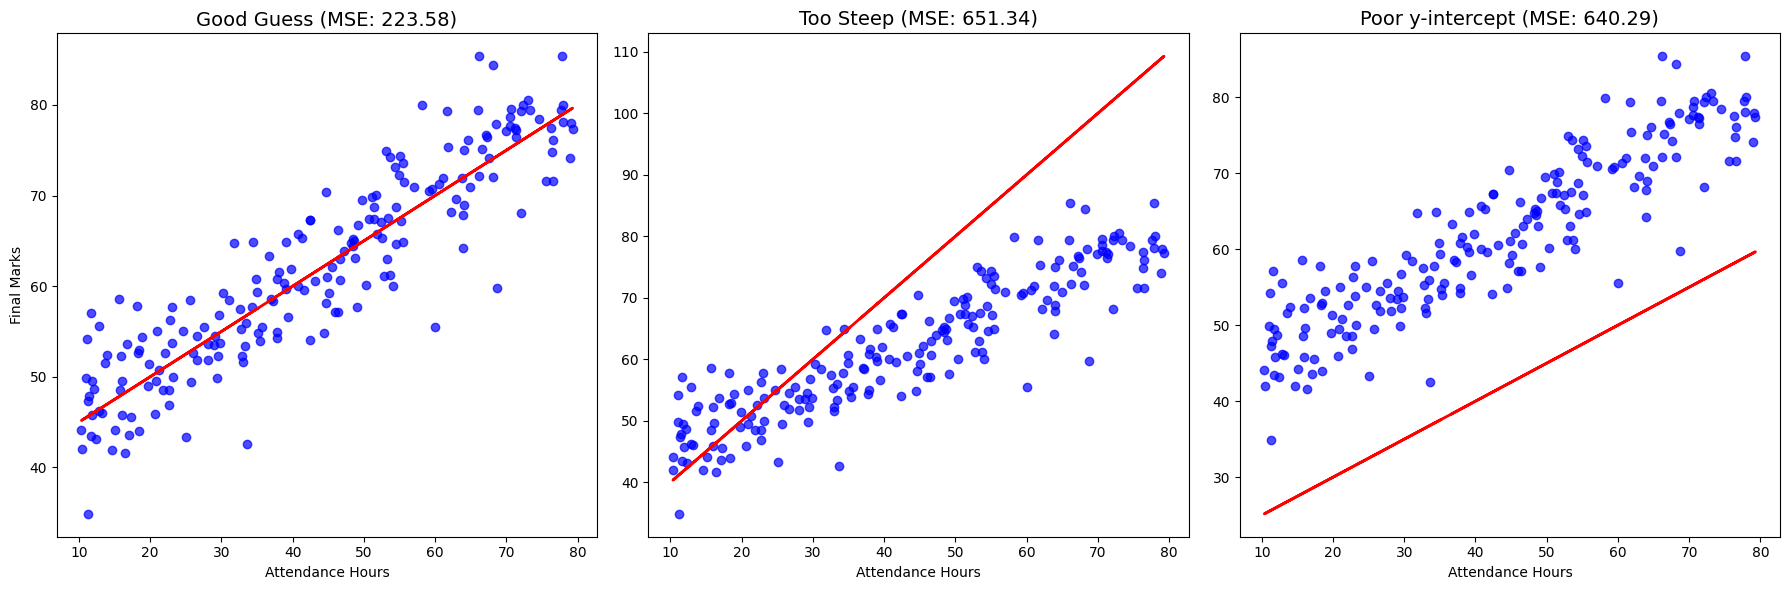

In [19]:
# Experiment 1: A good guess for a line.
m1, b1 = 0.5, 40
mse1 = mean_squared_error(m1, b1, X_test, y_test)
y_pred1 = m1 * X_test + b1

# Experiment 2: A line that is too steep.
m2, b2 = 1.0, 30
mse2 = mean_squared_error(m2, b2, X_test, y_test)
y_pred2 = m2 * X_test + b2

# Experiment 3: A line with a poor y-intercept.
m3, b3 = 0.5, 20
mse3 = mean_squared_error(m3, b3, X_test, y_test)
y_pred3 = m3 * X_test + b3

# Plot the different lines to see the difference.
plt.figure(figsize=(18, 6))

plt.subplot(1, 3, 1)
plt.scatter(X_test, y_test, color='blue', alpha=0.7)
plt.plot(X_test, y_pred1, color='red', linewidth=2)
plt.title(f'Good Guess (MSE: {mse1:.2f})', fontsize=14)
plt.xlabel('Attendance Hours')
plt.ylabel('Final Marks')

plt.subplot(1, 3, 2)
plt.scatter(X_test, y_test, color='blue', alpha=0.7)
plt.plot(X_test, y_pred2, color='red', linewidth=2)
plt.title(f'Too Steep (MSE: {mse2:.2f})', fontsize=14)
plt.xlabel('Attendance Hours')

plt.subplot(1, 3, 3)
plt.scatter(X_test, y_test, color='blue', alpha=0.7)
plt.plot(X_test, y_pred3, color='red', linewidth=2)
plt.title(f'Poor y-intercept (MSE: {mse3:.2f})', fontsize=14)
plt.xlabel('Attendance Hours')

plt.tight_layout()
plt.show()


Our goal is to find the m and b that give us the absolute minimum MSE. While we can do this manually with more complex algorithms like Gradient Descent, libraries like scikit-learn automate this process for us.



<span style= "color: deepskyblue; font-size:32px;">2. Building the Model with Scikit-learn</span>


Now that we understand the underlying principle, let's use a professional library to find the optimal m and b for our data. scikit-learn is a powerful machine learning library that makes this process very efficient.

In [20]:
#import sys
#!{sys.executable} -m pip install scikit-learn

from sklearn.linear_model import LinearRegression

# Create and fit the linear regression model.
model = LinearRegression()
model.fit(X_train, y_train)

# Print the model's coefficients.
print(f"The optimal slope (m) is: {model.coef_[0]:.4f}")
print(f"The optimal y-intercept (b) is: {model.intercept_:.4f}")

The optimal slope (m) is: 0.4874
The optimal y-intercept (b) is: 41.0749


Scikit-learn finds the values of 
𝑚
m and 
𝑏
b that give the lowest MSE. The slope 
𝑚
m shows how much the final mark increases for each extra hour of attendance, while the intercept 
𝑏
b is the expected mark when attendance is zero.

<span style = "color: deepskyblue; font-size: 32px;">**Step 4: Making a Prediction**</span>

#### 1. predict single data, attendance hour = 45
Now that our model is trained, we can use it to make predictions. Let's see what marks a student might get if they attend a certain number of hours.

In [21]:
# Let's predict the final marks for a student with 45 hours of attendance.
hours_to_predict = np.array([[45]])
predicted_marks = model.predict(hours_to_predict)

print(f"Predicted marks for 45 attendance hours: {predicted_marks[0]:.4f}")

Predicted marks for 45 attendance hours: 63.0095


#### 2. predict all test data that we split from dataset

In [22]:
# Generate the predicted values for all our data points to plot the line.
y_pred = model.predict(X_test)

<span style = "color: deepskyblue; font-size:32px;"> **Step 5: Visualizing the Regression Line**</span>

Finally, let's put it all together and visualize our final model. We will plot the original data points and then add the regression line scikit-learn found for us. This plot will clearly show how well our linear model fits the data.

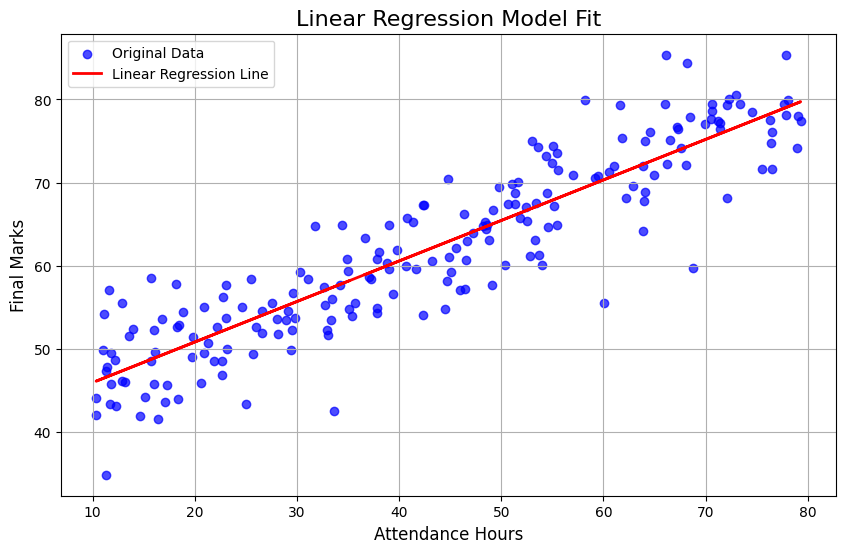

In [23]:

# Create a new scatter plot with the regression line.
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color='blue', alpha=0.7, label='Original Data')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Linear Regression Line')
plt.title('Linear Regression Model Fit', fontsize=16)
plt.xlabel('Attendance Hours', fontsize=12)
plt.ylabel('Final Marks', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()


<spane style="color:deepskyblue">The red line is our linear regression model. It's the "best fit" line that minimizes the cost function, providing a simple yet powerful way to model the relationship between study hours and final marks.</span>